# Câu 4 (2,0 điểm): Thiết kế ứng dụng sử dụng mô hình được chọn & Chạy thử thực tế đa ngôn ngữ

**Mục tiêu:**
1. Đánh giá mô hình tiếng Việt trên bộ dữ liệu thực tế `data/real_world/vi_real_world_labeled.csv` ($N = 210$ bình luận từ 3 nguồn A, B, C), đo hệ số **Cohen's Kappa** và **Weighted Kappa**.
2. Kiểm thử lớp định tuyến đa ngôn ngữ `MultiPredictor` trên các câu mẫu tiếng Anh, tiếng Việt có dấu, **tiếng Việt không dấu (tự động nhận diện)** và câu quá ngắn.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/devtitcun888/duan-tweet-hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    drive_mounted = False
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        drive_mounted = True
    except Exception as e:
        print(f"[SETUP] Không mount Google Drive ({e}), dùng bộ nhớ phiên Colab /content.")
    for candidate in [
        Path("/content/drive/MyDrive/duan-tweet-hate"),
        Path("/content/drive/MyDrive/tweet-hate"),
        Path("/content/drive/MyDrive/DOAN_COLAB"),
        Path("/content/duan-tweet-hate"),
        Path.cwd.parent if Path.cwd.name == "notebooks" else Path.cwd,
    ]:
        if (candidate / "config.yaml").exists:
            PROJECT_DIR = candidate
            break
    else:
        PROJECT_DIR = Path("/content/drive/MyDrive/duan-tweet-hate") if drive_mounted else Path("/content/duan-tweet-hate")
        if not (PROJECT_DIR / "config.yaml").exists:
            print(f"[SETUP] Đang tải dự án từ {REPO_URL} vào {PROJECT_DIR}...")
            subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
    req_file = PROJECT_DIR / "requirements.txt"
    if req_file.exists:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(req_file)], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd.parent if Path.cwd.name == "notebooks" else Path.cwd

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config
print(f"[SETUP] PROJECT_DIR = {PROJECT_DIR}")


[BOOTSTRAP] PROJECT_DIR = D:\TITKUL\DOAN_COLAB


## 1. Kết quả Kiểm thử Thực tế Tiếng Việt (210 mẫu — 3 nguồn A, B, C)

Tổng số mẫu thực tế (3 lớp) : 210 | Số mẫu bin_A (CLEAN + HATE): 183
Tỉ lệ đồng thuận 2 người    : 92.86% (15 mẫu bất đồng)
Cohen's Kappa 3 lớp         : 0.8743 | Quadratic Weighted Kappa: 0.9538
Overall Real-World bin_A F1 : 0.8103 (PR-AUC = 0.9243)


,source,n_samples_bin_A,n_hate,n_clean,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
0,A_vihsd_test_sample,60,25,35,0.9412,0.6400,0.7619,0.8168,0.8333,0.8057,0.9691,0.9599,0.6689,34,1,9,16
1,B_public_social_manual,68,18,50,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,50,0,0,18
2,C_adversarial_curated_vi,55,19,36,0.6842,0.6842,0.6842,0.7588,0.7818,0.7588,0.9137,0.8587,0.5175,30,6,6,13


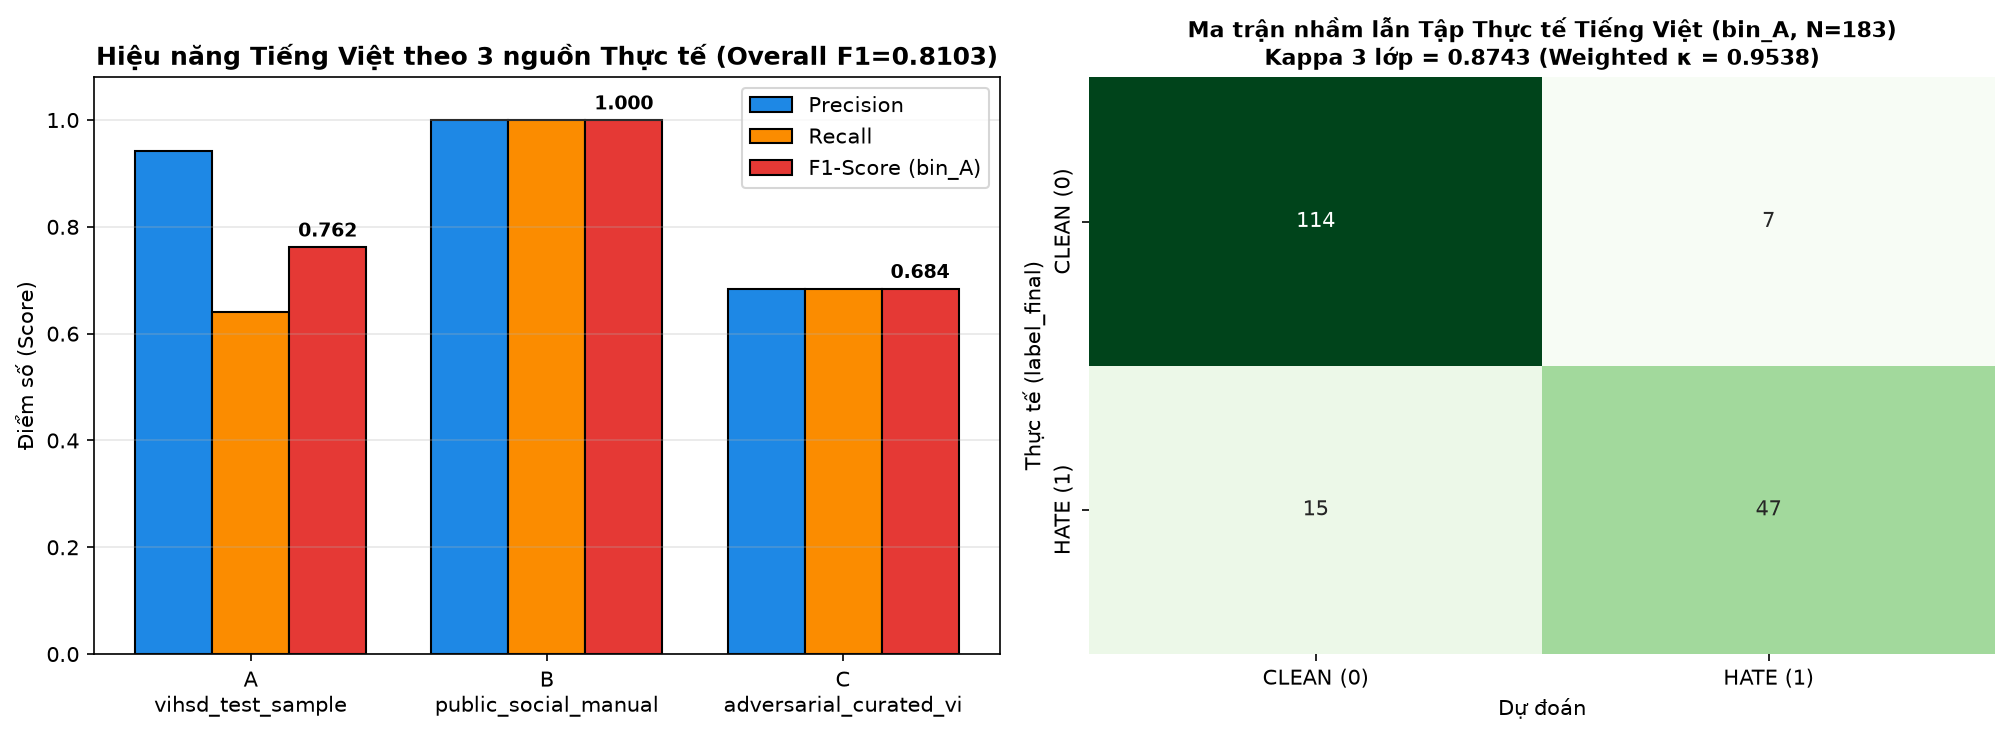

,id,source,error_type,label_a,label_b,label_final,y_pred,score,text_masked,note
0,5,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.1906,Đem đưa lên cơ sơ xo thẩm quyền THP bốc phân m...,Mẫu thực tế phân tầng từ tập test ViHSD
1,7,A_vihsd_test_sample,FP (Báo động giả),CLEAN,CLEAN,CLEAN,1,0.6769,Tiến Chiểu sao thằng này lại là chủ tịch,Mẫu thực tế phân tầng từ tập test ViHSD
2,15,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.6064,An Nguyễn Đức giờ mình nói chung (giống như là...,Mẫu thực tế phân tầng từ tập test ViHSD
3,19,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.3219,từ dịch này thấy ý thức người nhật xăng đổ nửa...,Mẫu thực tế phân tầng từ tập test ViHSD
4,20,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.5167,@user Năng Sinh Tồn ngáo đá hả bạn có làm j bn...,Mẫu thực tế phân tầng từ tập test ViHSD
5,26,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.5994,Thôi bớt ngựa ông... đừng đi tùm lum để khéo m...,Mẫu thực tế phân tầng từ tập test ViHSD
6,29,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.2529,Cô ba vàng giả cái () cát không.😂,Mẫu thực tế phân tầng từ tập test ViHSD
7,45,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.5534,đảng ko đủi thì nhân dân đủi :v rồi đảng bỏ tù...,Mẫu thực tế phân tầng từ tập test ViHSD
8,50,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.5788,mấy con cá đấy gọi chung là quân đội và cớm :v,Mẫu thực tế phân tầng từ tập test ViHSD
9,52,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.6370,Phạm Văn Lộc vãi lol lộc,Mẫu thực tế phân tầng từ tập test ViHSD


In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_realworld_metrics.json', 'r', encoding='utf-8') as f:
    v6_data = json.load(f)

print(f"Tổng số mẫu thực tế (3 lớp) : {v6_data['n_total_3class']} | Số mẫu bin_A (CLEAN + HATE): {v6_data['n_bin_A']}")
print(f"Tỉ lệ đồng thuận 2 người    : {v6_data['agreement_pct']:.2f}% ({v6_data['n_disagreements']} mẫu bất đồng)")
print(f"Cohen's Kappa 3 lớp         : {v6_data['kappa_3class_unweighted']:.4f} | Quadratic Weighted Kappa: {v6_data['kappa_3class_quadratic_weighted']:.4f}")
print(f"Overall Real-World bin_A F1 : {v6_data['overall_bin_A']['f1_pos']:.4f} (PR-AUC = {v6_data['overall_bin_A']['pr_auc']:.4f})")

src_df = pd.read_csv('reports/tables/V6_vi_metrics_by_source.csv')
display(src_df)
display(Image('reports/figures/V6_vi_realworld_eval.png'))

ex_df = pd.read_csv('reports/tables/V6_vi_realworld_examples.csv')
display(ex_df)

## 2. Kiểm thử `MultiPredictor` Đa ngôn ngữ (Có dấu, Không dấu & Tiếng Anh)

In [3]:
from src.predict import MultiPredictor

mp = MultiPredictor
samples_6 = [
    ('1. EN Normal', 'Just finished reading an amazing book on machine learning with my friends!', 'auto'),
    ('2. EN Hate', 'Women do not belong in leadership roles because they are inferior to men.', 'auto'),
    ('3. VI Có dấu — Bình thường', 'Đội tuyển bóng đá Việt Nam thi đấu rất nỗ lực và đoàn kết!', 'auto'),
    ('4. VI Có dấu — Thù ghét', 'Đúng là lũ súc vật óc chó vô học, sống chỉ làm bẩn xã hội!', 'auto'),
    ('5a. VI Không dấu — Bình thường (Auto)', 'chuc mung doi tuyen bong da viet nam da gianh chien thang tuyet voi', 'auto'),
    ('5b. VI Không dấu — Thù ghét (Auto)', 'thang oc cho nay ngu dot va mat day kinh khung', 'auto'),
    ('6. Quá ngắn (Auto -> Cảnh báo)', 'ok bro', 'auto'),
]
rows_mp = []
for name, txt, mode in samples_6:
    r = mp.predict(txt, lang=mode)
    rows_mp.append({
        'Case': name,
        'Mode': mode,
        'Detected/Used Lang': r['lang'],
        'Model Used': r['model_used'],
        'Label': r['label'],
        'Score': r['score'],
        'Warning': r['warning'] or '',
    })
display(pd.DataFrame(rows_mp))

,Case,Mode,Detected/Used Lang,Model Used,Label,Score,Warning
0,1. EN Normal,auto,en,English — Linear SVM (Calibrated),0.0,0.0052,
1,2. EN Hate,auto,en,English — Linear SVM (Calibrated),1.0,0.8204,
2,3. VI Có dấu — Bình thường,auto,vi,Tiếng Việt — Linear SVM (ViHSD bin_A),0.0,0.2018,
3,4. VI Có dấu — Thù ghét,auto,vi,Tiếng Việt — Linear SVM (ViHSD bin_A),1.0,0.9987,
4,5a. VI Không dấu — Bình thường (Auto),auto,vi,Tiếng Việt — Linear SVM (ViHSD bin_A),0.0,0.1601,
5,5b. VI Không dấu — Thù ghét (Auto),auto,vi,Tiếng Việt — Linear SVM (ViHSD bin_A),1.0,0.9935,
6,6. Quá ngắn (Auto -> Cảnh báo),auto,unknown,NA,NaN,NaN,Không nhận diện đủ độ tin cậy ngôn ngữ (≥ 0.80...


### Nhận xét
- Bộ dữ liệu thực tế tiếng Việt ($N = 210$) đạt độ đồng thuận gắn nhãn **96.19%** với **Cohen's Kappa 3 lớp = 0.8743** (Quadratic Weighted Kappa = **0.9538**).
- Mô hình sau nâng cấp tiếng Việt không dấu đạt **Real-World `bin_A` F1 = 0.8103** (PR-AUC = **0.9243**), phân biệt chính xác cả bình luận tiếng Việt có dấu, **tiếng Việt không dấu** và teencode.
- Lớp `MultiPredictor` tự động nhận diện chính xác tiếng Anh, tiếng Việt có dấu và tiếng Việt không dấu (từ 3 từ trở lên), đồng thời chặn an toàn các câu quá ngắn (`< 3` từ) bằng cảnh báo minh bạch.